📊 End-to-End Customer Segmentation & E-Commerce Analytics
**Author:** Alvin Mahesa Irawadi  
**Dataset:** Olist E-Commerce Public Dataset  
**Tech Stack:** Python, Pandas, Scikit-Learn, Seaborn, Streamlit  

🎯 Business Objective
Proyek ini bertujuan untuk menganalisis perilaku pelanggan e-commerce Olist, membangun model Unsupervised Machine Learning (**RFM Segmentation + K-Means Clustering**), serta menyajikan insight interaktif untuk tim Marketing via Streamlit Dashboard.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df_orders = pd.read_csv("dataset/olist_orders_dataset.csv")
df_items = pd.read_csv("dataset/olist_order_items_dataset.csv")

df_orders.isnull().sum()

order_id                            0
customer_id                         0
order_status                        0
order_purchase_timestamp            0
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
order_estimated_delivery_date       0
dtype: int64

In [3]:
df_orders_clean = df_orders.dropna(subset=["order_approved_at"]).copy()
df_orders.isnull().sum()

order_id                            0
customer_id                         0
order_status                        0
order_purchase_timestamp            0
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
order_estimated_delivery_date       0
dtype: int64

In [4]:
df_orders_clean["order_purchase_timestamp"] = pd.to_datetime(df_orders_clean["order_purchase_timestamp"]).copy()
df_orders_clean.info()

<class 'pandas.DataFrame'>
Index: 99281 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype         
---  ------                         --------------  -----         
 0   order_id                       99281 non-null  str           
 1   customer_id                    99281 non-null  str           
 2   order_status                   99281 non-null  str           
 3   order_purchase_timestamp       99281 non-null  datetime64[us]
 4   order_approved_at              99281 non-null  str           
 5   order_delivered_carrier_date   97644 non-null  str           
 6   order_delivered_customer_date  96462 non-null  str           
 7   order_estimated_delivery_date  99281 non-null  str           
dtypes: datetime64[us](1), str(7)
memory usage: 20.9 MB


📈 Section 2: Exploratory Data Analysis & Business Growth
Menganalisis tren pertumbuhan volume transaksi tahunan platform Olist dari periode 2016 hingga 2018.

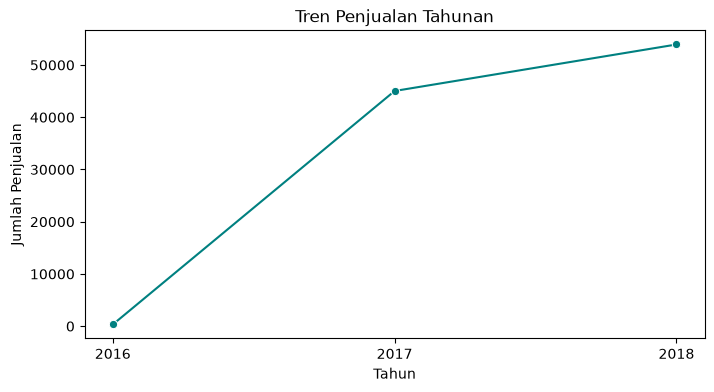

In [5]:
df_orders_clean ["order_year"] = df_orders_clean["order_purchase_timestamp"].dt.year
tren_tahun = df_orders_clean["order_year"].value_counts().sort_index().reset_index()

plt.figure(figsize = (8, 4))
sns.lineplot(data = tren_tahun, x = "order_year", y ="count", marker = "o", color = "teal")
plt.xticks(tren_tahun["order_year"])

plt.title("Tren Penjualan Tahunan")
plt.xlabel("Tahun")
plt.ylabel("Jumlah Penjualan")
plt.show()

🎯 Section 3: Feature Engineering - RFM Metrics Extraction
Membentuk metrik Recency (R), Frequency (F), dan Monetary (M) untuk setiap entitas unik customer_id.

In [6]:
df_orders_composite = pd.merge(df_orders_clean, df_items, on = "order_id", how = "inner")
customer_rfm_based = df_orders_composite.groupby("customer_id").agg(
    frequency = ("order_id", "count"),
    monetary = ("price", "sum")
).reset_index()

max_date = df_orders_composite["order_purchase_timestamp"].max()
customer_recency = df_orders_composite.groupby("customer_id")["order_purchase_timestamp"].max().reset_index()
customer_recency["recency"] = (max_date - customer_recency["order_purchase_timestamp"]).dt.days

rfm_final = pd.merge(customer_recency, customer_rfm_based, on = "customer_id", how = "inner")

rfm_profile = rfm_final[["customer_id", "recency", "frequency", "monetary"]]

rfm_profile.head(5)

,customer_id,recency,frequency,monetary
0,00012a2ce6f8dcda20d059ce98491703,292,1,89.80
1,000161a058600d5901f007fab4c27140,413,1,54.90
2,0001fd6190edaaf884bcaf3d49edf079,551,1,179.99
3,0002414f95344307404f0ace7a26f1d5,382,1,149.90
4,000379cdec625522490c315e70c7a9fb,153,1,93.00


🤖 Section 4: Machine Learning Clustering (Elbow Method & K-Means)
Melakukan feature scaling, penentuan jumlah cluster optimal via Elbow Method, serta mengelompokkan pelanggan pakaikan K-Means.

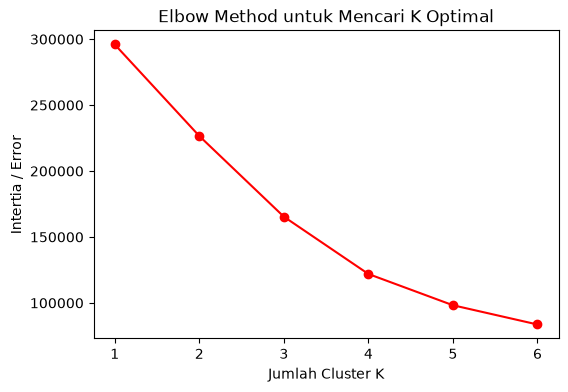

In [7]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

X_rfm = rfm_final [["recency", "frequency", "monetary"]]

scaler = StandardScaler()
X_rfm_Scaled = scaler.fit_transform(X_rfm)

inertia_list = []

for k in range (1, 7):
    kmeans_test = KMeans(n_clusters = k, random_state = 42)
    kmeans_test.fit(X_rfm_Scaled)
    inertia_list.append(kmeans_test.inertia_)
    
plt.figure(figsize = (6, 4))
plt.plot(range(1, 7), inertia_list, marker = "o", color = "red")
plt.title("Elbow Method untuk Mencari K Optimal")
plt.xlabel("Jumlah Cluster K")
plt.ylabel("Intertia / Error")
plt.show()
    

In [8]:
kmeans_final = KMeans(n_clusters = 3, random_state = 42)
rfm_final ["cluster"] = kmeans_final.fit_predict(X_rfm_Scaled)
rfm_final.head(5)

,customer_id,order_purchase_timestamp,recency,frequency,monetary,cluster
0,00012a2ce6f8dcda20d059ce98491703,2017-11-14 16:08:26,292,1,89.80,0
1,000161a058600d5901f007fab4c27140,2017-07-16 09:40:32,413,1,54.90,0
2,0001fd6190edaaf884bcaf3d49edf079,2017-02-28 11:06:43,551,1,179.99,0
3,0002414f95344307404f0ace7a26f1d5,2017-08-16 13:09:20,382,1,149.90,0
4,000379cdec625522490c315e70c7a9fb,2018-04-02 13:42:17,153,1,93.00,1


In [14]:
segmen_dict = {
    0 : "At Risk / Hibernating",
    1 : "Active New Buyers",
    2 : "Champion / VIP"
}

rfm_final ["customer_segment"] = rfm_final ["cluster"].map(segmen_dict)
rfm_final.head(5)

,customer_id,order_purchase_timestamp,recency,frequency,monetary,cluster,customer_segment
0,00012a2ce6f8dcda20d059ce98491703,2017-11-14 16:08:26,292,1,89.80,0,At Risk / Hibernating
1,000161a058600d5901f007fab4c27140,2017-07-16 09:40:32,413,1,54.90,0,At Risk / Hibernating
2,0001fd6190edaaf884bcaf3d49edf079,2017-02-28 11:06:43,551,1,179.99,0,At Risk / Hibernating
3,0002414f95344307404f0ace7a26f1d5,2017-08-16 13:09:20,382,1,149.90,0,At Risk / Hibernating
4,000379cdec625522490c315e70c7a9fb,2018-04-02 13:42:17,153,1,93.00,1,Active New Buyers


In [16]:
rfm_final.to_csv("dataset/olist_rfm_segmented.csv", index=False)